# Weighted importance sampling (WIS): CQL policy value vs. clinician baseline

Uses BC's `log_prob_of_action` as the behavior-policy density and CQL's
`log_prob_for_wis` (evaluation density built around CQL's deterministic
action, using BC's per-state std as bandwidth) as the target-policy
density. Seed pairing follows the same discipline as CQL<->FQE pairing
(evaluate_fqe_final_seeds.py): CQL seed *i* is evaluated ONLY against its
matched BC seed *i*, matched via each model's own `results.json`.

Functions live in `evaluate_wis.py`; this notebook just runs them and
displays the plots/tables, per the project's analysis-workflow convention.

**Run on val first.** Once the weight diagnostics look sane, switch
`ACTIVE_SPLIT` to `"test"` below and rerun the same cells for the final
reported numbers.

In [10]:
import sys
import os
from pathlib import Path
import importlib
import json

import numpy as np
import matplotlib.pyplot as plt
import torch

%load_ext autoreload
%autoreload 2

repo_root = Path("/home/jake/Documents/AI_Clinician/ai_clinician_pediatric_rl")
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

import src.rl.evaluate_cql_alpha_sweep as eval_cql
import src.rl.evaluate_terminal_reward_models as etm
import src.rl.evaluate_wis as evwis
import src.rl.evaluate_bc_final_seeds as eval_bc


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [13]:
# --- same cohort selection convention as evaluate_cql_alpha_sweep.ipynb / evaluate_cql_final_seeds.ipynb ---
cohort = "picu"
health_cohort = "picu"  # dynamic deephit trained on all picu patients, not just sepsis patients

dynamic_deephit_model_dir = "/home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/choc/five_splits/split_0/sepsis/intake-vis/picu/final_model"
cql_model_dir = "/home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset"
bc_model_dir = "/home/jake/Documents/AI_Clinician/models/rl_models/choc/bc_with_logprobs/split_0/sepsis/intake-vis/picu_patients"

In [3]:
# state_dim, same as evaluate_cql_alpha_sweep.ipynb
dynamic_deephit_dir = eval_cql.get_model_dirs(dynamic_deephit_model_dir)[0]
with open(os.path.join(dynamic_deephit_dir, "results.json"), "r") as f:
    dynamic_deephit_results = json.load(f)
state_dim = dynamic_deephit_results['hyperparameters']['d_model']
print(f"State dimension: {state_dim}")


No choc directories found in /home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/choc/five_splits/split_0/sepsis/intake-vis/picu/final_model
Found model directory: /home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/choc/five_splits/split_0/sepsis/intake-vis/picu/final_model/unknown_cx3-20-1_20260821-202508_49e52257
State dimension: 128


In [16]:
# --- load 5 final CQL (health-score) models ---
cql_health_score_fixed_alpha_model_dir = os.path.join(cql_model_dir, "health_score_change_only", "fixed_alpha")
cql_model_dirs = eval_cql.get_model_dirs(cql_health_score_fixed_alpha_model_dir)

cql_models = []
for model_dir in cql_model_dirs:
    actor, critic, health_score_config_manager, health_score_hyperparams = etm.load_actor_and_critic(
        model_dir=model_dir, model_type='cql', state_dim=state_dim,
    )
    print(f"Loaded CQL model from {model_dir}, seed={health_score_hyperparams.get('seed')}")
    cql_models.append((actor, critic, health_score_config_manager, health_score_hyperparams))


Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/health_score_change_only/fixed_alpha/choc_cql_with_logprobs_intake-vis_best_hyperparameters_fixed_cql_alpha_20260913_223042/unknown_cx3-20-1_20260913-235751_073683e4
Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/health_score_change_only/fixed_alpha/choc_cql_with_logprobs_intake-vis_best_hyperparameters_fixed_cql_alpha_20260913_223042/unknown_cx3-20-1_20260913-225924_24f16bd0
Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/health_score_change_only/fixed_alpha/choc_cql_with_logprobs_intake-vis_best_hyperparameters_fixed_cql_alpha_20260913_223042/unknown_cx3-20-1_20260913-232805_87a9aaa

In [17]:
GAMMA = health_score_hyperparams['discount']

In [18]:
# first, load the dynamic deephit hyperparameters so we can get the state dimension
dynamic_deephit_dir = eval_cql.get_model_dirs(dynamic_deephit_model_dir)[0]
print(f"Dynamic DeepHit model directory: {dynamic_deephit_dir}")
# load results.json from dynamic_deephit_dir
with open(os.path.join(dynamic_deephit_dir, "results.json"), "r") as f:
    dynamic_deephit_results = json.load(f)
state_dim = dynamic_deephit_results['hyperparameters']['d_model']
print(f"State dimension from dynamic deephit hyperparameters: {state_dim}")

# find folder inside bc_dir that ends "with_seeds"
bc_with_seeds_dir = None
for folder in os.listdir(bc_model_dir):
    if folder.endswith("with_seeds"):
        bc_with_seeds_dir = os.path.join(bc_model_dir, folder)
        break

if bc_with_seeds_dir is None:
    raise ValueError("Could not find folder in bc_dir that ends with 'with_seeds'")

print(f"BC with seeds directory: {bc_with_seeds_dir}")

bc_model_dirs = etm.get_model_dirs(bc_with_seeds_dir)

print(f"BC model directories: {bc_model_dirs}")

bc_models = []
for model_dir in bc_model_dirs:
    # load health score sarsa model
    actor, config_manager, hyperparams = eval_bc.load_actor(reward_type='health_score', model_dir=model_dir, state_dim=state_dim)
    bc_models.append((actor, config_manager, hyperparams))


No choc directories found in /home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/choc/five_splits/split_0/sepsis/intake-vis/picu/final_model
Found model directory: /home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/choc/five_splits/split_0/sepsis/intake-vis/picu/final_model/unknown_cx3-20-1_20260821-202508_49e52257
Dynamic DeepHit model directory: /home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/choc/five_splits/split_0/sepsis/intake-vis/picu/final_model/unknown_cx3-20-1_20260821-202508_49e52257
State dimension from dynamic deephit hyperparameters: 128
BC with seeds directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/bc_with_logprobs/split_0/sepsis/intake-vis/picu_patients/choc_bc_with_logprobs_intake-vis_best_hyperparameters_20260918_223049_with_seeds
No choc directories found in /home/jake/Documents/AI_Clinician/models/rl_models/choc/bc_with_logprobs/split_0/sepsis/intake-vis/picu_patients/choc_bc_with_logprobs_intake-vis_best

In [19]:
health_score_config_manager.data_config['unit_stay_ids_path'] = os.path.join(
    health_score_config_manager.get_data_dir, 'cohorts',
    'icu_units',
    f"{health_score_config_manager.unit.lower()}_stay_ids.csv"
)

health_score_config_manager.data_config['age_stay_ids_path'] = os.path.join(
    health_score_config_manager.get_data_dir, 'cohorts',
    'age', 'pediatric_stay_ids.csv'
)

processors = {}
processors['train'], processors['val'], processors['test'] = etm.load_data(health_score_config_manager, health_score_hyperparams)  

using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type


## Sanity check: confirm CQL<->BC seed pairing before running anything else

This just prints the matched pairs (and raises if any seed is missing/duplicated
on either side) -- catching a pairing mistake here is a lot cheaper than
catching it after a full WIS run.

In [39]:
pairs, cql_models_with_seeds, bc_models_with_seeds = evwis.match_cql_bc_pairs(cql_models, bc_models)

CQL seeds loaded: [0, 1, 2, 3, 4]
BC seeds loaded:  [0, 1, 2, 3, 4]
Matched 5 (CQL, BC) pairs by results.json seed: [0, 1, 2, 3, 4]


## Run WIS -- validation set first

`ACTIVE_SPLIT` controls which processor is used everywhere below. Leave
this at `"val"` until the weight diagnostics (ESS, top-1% weight
concentration) look reasonable, then switch to `"test"` and rerun.

In [43]:
ACTIVE_SPLIT = "val"
active_processor = processors[ACTIVE_SPLIT]

results = evwis.run_wis_across_seeds(
    cql_models_with_seeds, bc_models_with_seeds, 
    active_processor,
    gamma=GAMMA,
    cap_percentile=None,   # no capping on this first pass -- see capping comparison below
    n_bootstrap=1000,
    random_state=0,
)

CQL seeds loaded: [0, 1, 2, 3, 4]
BC seeds loaded:  [0, 1, 2, 3, 4]
Matched 5 (CQL, BC) pairs by results.json seed: [0, 1, 2, 3, 4]

=== Seed 0 ===
  Clinician baseline (logged) return: 3.4876 +/- 0.3981 (SEM)
  Trajectory-level WIS: 5.0934  [-4.0006, 5.0934]  ESS=1.0/240 (0.4%)
  Stepwise WIS:         10.3168  [1.5392, 12.1101]
  Top-1% of trajectories hold 100.0% of total weight (max single trajectory: 100.0%)

=== Seed 1 ===
  Clinician baseline (logged) return: 3.4876 +/- 0.3981 (SEM)
  Trajectory-level WIS: 5.0934  [-1.1558, 5.0934]  ESS=1.0/240 (0.4%)
  Stepwise WIS:         6.1694  [0.4683, 14.4059]
  Top-1% of trajectories hold 100.0% of total weight (max single trajectory: 100.0%)

=== Seed 2 ===
  Clinician baseline (logged) return: 3.4876 +/- 0.3981 (SEM)
  Trajectory-level WIS: 12.7680  [-1.1558, 12.7680]  ESS=1.0/240 (0.4%)
  Stepwise WIS:         28.8515  [-2.1178, 34.8272]
  Top-1% of trajectories hold 100.0% of total weight (max single trajectory: 100.0%)

=== Seed 3 ==

In [44]:
dominant = evwis.find_dominant_trajectories(
    results[0]["trajectories"], results[0]["trajectory_wis"], top_k=3,
)
evwis.print_dominant_trajectory_report(dominant, active_processor, results[0]["bc_actor"])

--- rank 0: stay_id=1188052349, weight_frac=100.0%, length=889 ---
  Dominant timestep: 171 of 889 (global row 64004)
  Real logged action: fluid=0.8334, vaso=0.0000
  BC fire probability at this state: fluid_p=0.9571, vaso_p=0.0846
  behavior_lp=-5.809, target_lp=-1.159, log_ratio=4.651 (exp(log_ratio)=1.046e+02)
  Trajectory's total log-weight (sum over all 889 timesteps): 218.698
  Discounted return G_i for this trajectory: 5.0934

--- rank 1: stay_id=1185785426, weight_frac=0.0%, length=294 ---
  Dominant timestep: 293 of 294 (global row 8597)
  Real logged action: fluid=0.0535, vaso=0.0000
  BC fire probability at this state: fluid_p=0.4196, vaso_p=0.0330
  behavior_lp=-4.934, target_lp=0.744, log_ratio=5.678 (exp(log_ratio)=2.925e+02)
  Trajectory's total log-weight (sum over all 294 timesteps): 73.128
  Discounted return G_i for this trajectory: -1.1558

--- rank 2: stay_id=1186523976, weight_frac=0.0%, length=141 ---
  Dominant timestep: 55 of 141 (global row 26585)
  Real logg

In [45]:
_ = evwis.compare_dominant_trajectory_across_seeds(results, top_k=1)

 seed      stay_id  weight_frac     return
    0   1188052349       100.0%     5.0934
    1   1188052349       100.0%     5.0934
    2   1187935638       100.0%    12.7680
    3   1185785426        62.2%    -1.1558
    4   1188515320       100.0%    11.6682

4 distinct stay_ids dominate across 5 seeds (some repeats) -- partially structural, partially seed-dependent.


Spearman correlation, trajectory length vs. log-weight: rho=-0.487 (p=1.11e-15), n=240
Trajectory length: median=259, max=1402, 90th pctile=891


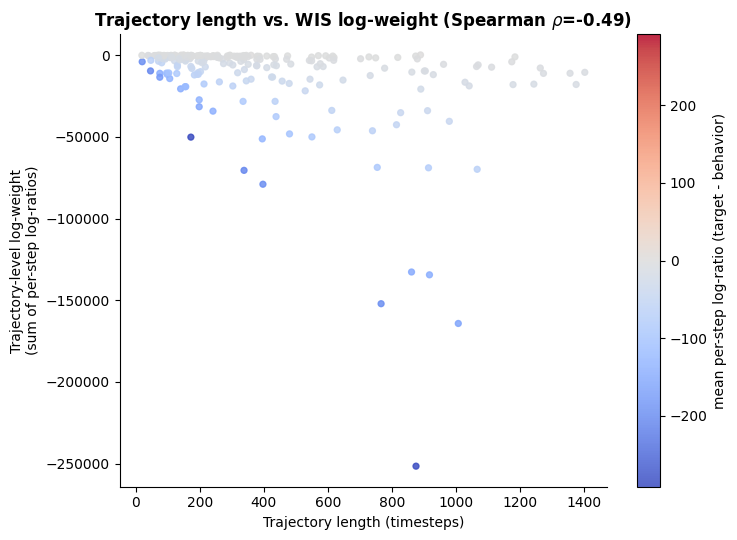

In [47]:
length_weight = evwis.compute_length_weight_relationship(
    results[0]["trajectories"], results[0]["trajectory_wis"],
)
fig = evwis.plot_length_vs_log_weight(length_weight)

In [48]:
np.median(length_weight["mean_log_ratio_per_step"])

-6.9050102405119995

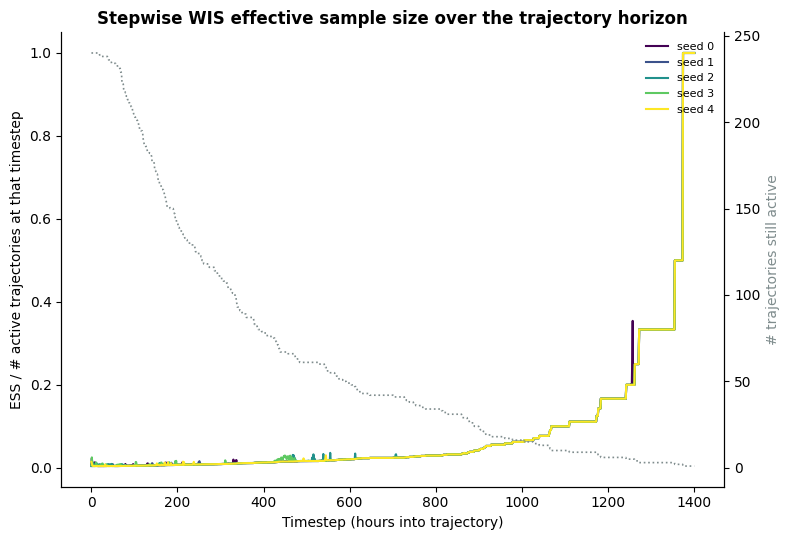

In [49]:
fig = evwis.plot_stepwise_ess_curve(results)

In [ ]:
fig = evwis.plot_wis_by_seed(
    results,
    title=f"WIS-estimated CQL policy value by seed ({ACTIVE_SPLIT} set)",
    save_path=os.path.join(cql_model_dir, f"wis_by_seed_{ACTIVE_SPLIT}.png"),
)
fig


**Note on comparing the two estimators:** trajectory-level and stepwise WIS 
will not numerically agree even under a null policy shift, because trajectories 
have different lengths -- stepwise WIS normalizes by the trajectories still active 
at each timestep, not by the fixed total N. A gap between the two on its own is not 
evidence of a bug; use the bootstrap CIs and the ESS curve below to judge which 
(if either) estimate to trust at the horizons involved.

In [ ]:
fig = evwis.plot_weight_diagnostics(
    results,
    save_path=os.path.join(cql_model_dir, f"wis_weight_diagnostics_{ACTIVE_SPLIT}.png"),
)
fig


In [ ]:
fig = evwis.plot_bootstrap_distributions(
    results,
    save_path=os.path.join(cql_model_dir, f"wis_bootstrap_distributions_{ACTIVE_SPLIT}.png"),
)
fig


In [ ]:
fig = evwis.plot_stepwise_ess_curve(
    results,
    save_path=os.path.join(cql_model_dir, f"wis_stepwise_ess_{ACTIVE_SPLIT}.png"),
)
fig


## Robustness check: capped vs. uncapped importance weights

Re-runs the same analysis with per-timestep log importance ratios capped
at the 1st/99th percentile (pooled across all timesteps), to check
whether the headline WIS values are being driven by a small number of
extreme single-timestep ratios -- the same kind of dominance BC's own
docstring flagged for the fluid gate specifically. If capped and
uncapped values diverge substantially, that's a sign the uncapped
estimate is not trustworthy on its own.

In [ ]:
results_capped = evwis.run_wis_across_seeds(
    cql_models, bc_models, cql_model_dirs, bc_model_dirs,
    active_processor,
    gamma=GAMMA,
    cap_percentile=1.0,
    n_bootstrap=1000,
    random_state=0,
)


In [ ]:
for r_raw, r_capped in zip(results, results_capped):
    assert r_raw["seed"] == r_capped["seed"]
    print(f"seed {r_raw['seed']}: "
          f"trajectory WIS raw={r_raw['trajectory_wis']['value']:.4f} vs capped={r_capped['trajectory_wis']['value']:.4f}  |  "
          f"stepwise WIS raw={r_raw['stepwise_wis']['value']:.4f} vs capped={r_capped['stepwise_wis']['value']:.4f}")


## Once val looks sane: rerun on test

Set `ACTIVE_SPLIT = "test"` in the cell above (under "Run WIS --
validation set first") and re-run every cell from that point down. Keep
both the val and test result dicts (e.g. rename to `results_val` /
`results_test` before switching) so you can compare val-vs-test weight
diagnostics as an extra sanity check, same as this project has done for
every other stage-3 analysis.